# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 4</span>

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Exercise 04.1

## Result

This section presents the results obtained from the molecular dynamics simulation, including thermodynamic property graphs and trajectory animations. 

The first graph illustrates the time evolution of the energy under the Verlet integration scheme. As expected for this system, the total energy remains stable, showing excellent conservation with negligible fluctuations.

To analyse the thermal state of the system, the calculation of the velocity distribution was integrated into the `measure` method of the `System` class, executed once the system reached equilibrium. Following standard procedures, the distribution is constructed as a histogram. The number of bins is allocated dynamically based on the input configuration read from `properties.dat`, with all measurement counters initialised to zero. 

To map the continuous velocity spectrum into discrete bins, a maximum velocity cutoff (in Lennard-Jones units) is defined. Velocities exceeding this threshold are excluded; this is a reliable approximation since the Maxwell-Boltzmann probability density function exhibits an exponential decrease at high velocities:

$$p(v,T) = \left( \frac{m}{2\pi k_B T} \right)^{3/2} 4\pi v^2 e^{-\frac{m v^2}{2 k_B T}}$$

By dividing the allowed velocity range into a finite number of bins, the algorithm counts the frequency of particles falling into each interval to compute the probability density.

The following figure displays the resulting histogram, complete with statistical error bars, of the particle velocities alongside the theoretical curve derived from the analytical solution, both expressed in LJ units. The simulation data were collected over 100 blocks with 2,000 steps per block. The velocity range $[0, v_{\max}]$ is divided into 30 bins, with $v_{\max} = 4\sqrt{T_{\rm input}} \simeq 5.51$ (input temperature $T_{\rm input} = 1.9$). The measured temperature of the system at equilibrium is $T^* = 1.047$ , and this value is used for the theoretical curve.

Finally, in the last cell of this notebook, you can view an animation illustrating the physical evolution and dynamics of the system throughout the simulation run.

---

**Exercise**

In Statistical Mechanics the Maxwell–Boltzmann distribution (<a href="https://en.wikipedia.org/wiki/Maxwell%E2%80%93Boltzmann_distribution" target="_blank">Link Wikipedia</a>) is a probability distribution used for describing particle speeds in idealized gases. However, rarefied gases at ordinary temperatures behave very nearly like an ideal gas and the Maxwell–Boltzmann speed distribution is an excellent approximation for such gases. For a 3D system its formula is:
$$p(v,T) = \left( \frac{m}{2\pi k_B T} \right)^{3/2} 4\pi v^2 e^{-\frac{m v^2}{2 k_B T}}$$

By using LJ reduced units (Lenght: $\sigma$; Energy: $\epsilon$; Mass: the mass, $m$, of the particles; Temperature: $\epsilon/k_B$; velocity: $\sqrt{\epsilon/m}$) its form becomes:
$$p(v^*,T^*) = \frac{1}{(2\pi T^*)^{3/2}} 4\pi (v^*)^2 e^{-\frac{(v^*)^2}{2 T^*}}$$

The NSL_SIMULATOR code already computes the total (internal) energy per particle, $E/N$, the potential energy per particle, $U/N$, the kinetic energy per particle, $K/N$, the temperature, $T$, and the pressure, $P$.

<span style="color:red">Include the calculation of the Maxwell–Boltzmann distribution, $p(v^*,T^*)$, inside your Molecular Dynamics code by using data blocking to obtain single block averages, progressive average values and progressive uncertainties for $p(v^*,T^*)$.</span>

Remember that, the Maxwell–Boltzmann distribution, $p(v^*,T^*)$, can be approximately computed as a **normalized histogram** on an appropriate interval $\left[ 0, v_{max}\right]$ and chosing the number of bins into which you want to divide this interval.

In [19]:
T_final = np.loadtxt("temperature.dat")[-1, 2]
d = np.loadtxt("pofv.dat")
dv = d[1, 1] - d[0, 1]
print("T (final progressive average) =", T_final)
print("v_max =", 30*dv, "  ->  T_input =", (30*dv/4)**2)

T (final progressive average) = 1.04706
v_max = 5.513619   ->  T_input = 1.8999996548225626


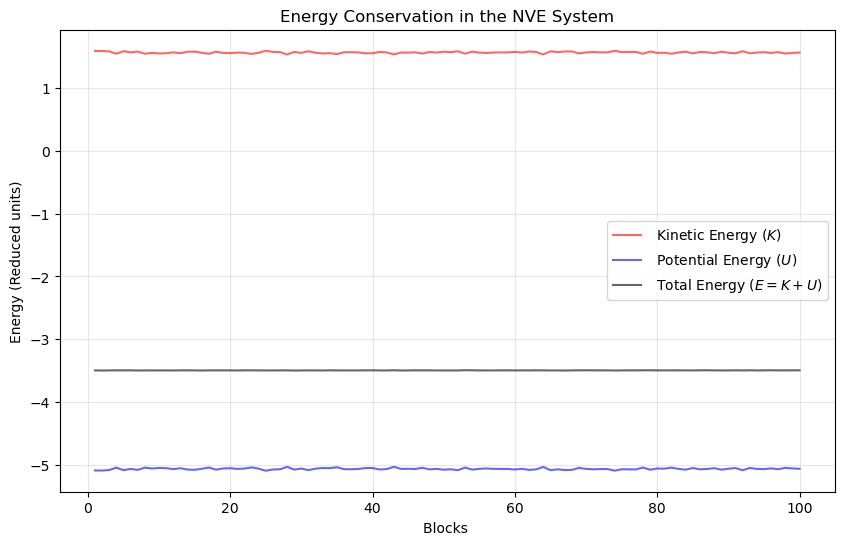

In [8]:


# Carico i dati
data1 = np.loadtxt("kinetic_energy.dat")
data2 = np.loadtxt("potential_energy.dat")
data3 = np.loadtxt("total_energy.dat")

# Definisco le x (blocchi) e le y (energie)
blocks = data1[:, 0]
ke = data1[:, 1]
pe = data2[:, 1]
tot=data3[:,1]

plt.figure(figsize=(10,6))

# Plot delle componenti
plt.plot(blocks, ke, label=' Kinetic Energy ($K$)', color='red', alpha=0.6)
plt.plot(blocks, pe, label=' Potential Energy ($U$)', color='blue', alpha=0.6)
plt.plot(blocks, tot, label=' Total Energy ($E=K+U$)', color='black', alpha=0.6)

# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Blocks ")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

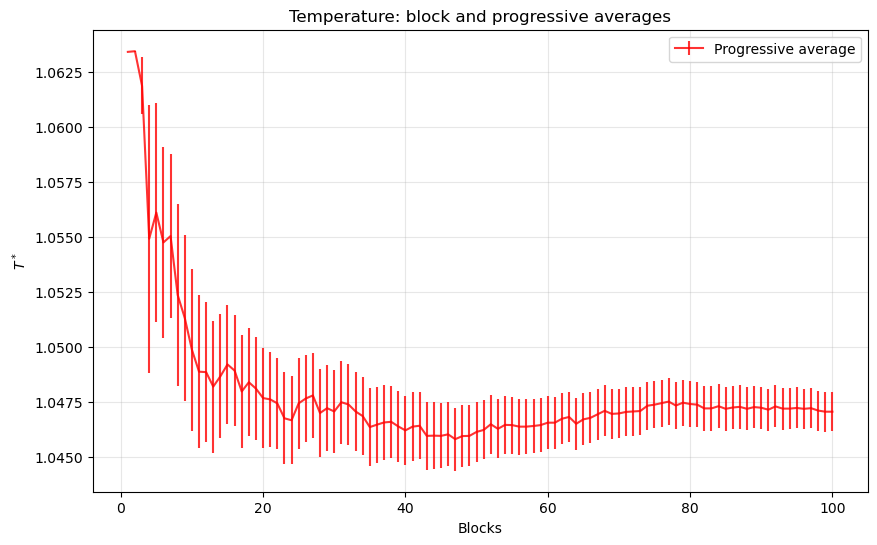

In [37]:
data4 = np.loadtxt("temperature.dat")
blocks_te = data4[:, 0]

plt.figure(figsize=(10, 6))
plt.errorbar(blocks_te, data4[:, 2], yerr=data4[:, 3], color='red', alpha=0.8,
             label='Progressive average')

plt.title("Temperature: block and progressive averages")
plt.xlabel("Blocks")
plt.ylabel(r"$T^*$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

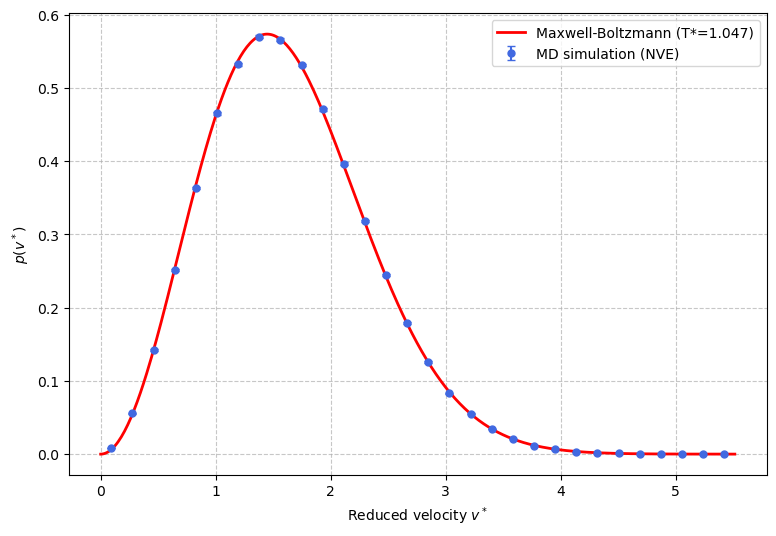

In [6]:
import numpy as np
import matplotlib.pyplot as plt

n_bins = 30                     
data = np.loadtxt("pofv.dat")
last = data[-n_bins:]            

v_sim    = last[:, 1]            # bin centre
ave_pofv = last[:, 3]            # progressive average
err_pofv = last[:, 4]            # progressive error

T_measured = np.loadtxt("temperature.dat")[-1, 2]   
dv = v_sim[1] - v_sim[0]
v_theory = np.linspace(0, v_sim[-1] + dv/2, 400)
f_v = 4*np.pi*(1/(2*np.pi*T_measured))**1.5 * v_theory**2 * np.exp(-v_theory**2/(2*T_measured))


plt.figure(figsize=(9, 6))
plt.errorbar(v_sim, ave_pofv, yerr=err_pofv, fmt='o', capsize=3, markersize=5,
             color='royalblue', label='MD simulation (NVE)')
plt.plot(v_theory, f_v, 'r-', lw=2, label=f'Maxwell-Boltzmann (T*={T_measured:.3f})')
plt.xlabel(r"Reduced velocity $v^*$")
plt.ylabel(r"$p(v^*)$")
plt.legend(); plt.grid(True, ls='--', alpha=0.7)
plt.show()  



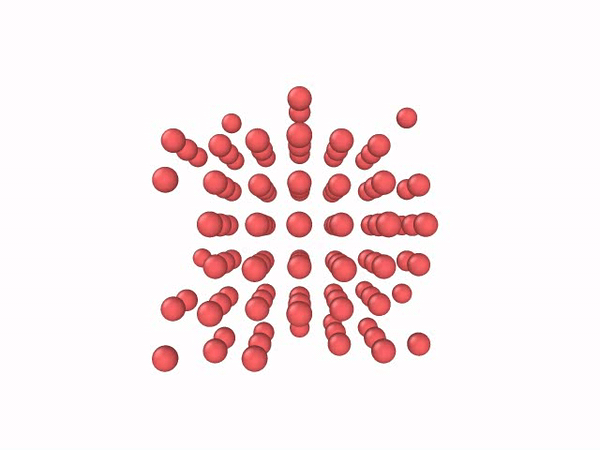

In [14]:
from IPython.display import Image
Image("simulazione.gif", width=600)